In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0016344314544237525 - 0.0009903466482917335im -0.0011032984631284962 - 0.0027103478992366926im … 0.0027043963077073843 - 0.001723384455659128im 0.0018539328306241343 + 0.0006595927967236834im; -8.197034131534809e-5 + 0.002645445401424484im 0.00140129127588519 - 0.0022720776093314186im … -0.0022208490933217444 - 0.0005829213360572225im -0.003631262309279266 - 0.0015025751005850675im; -0.0018037303502114563 + 0.0007378027480545248im -0.0018021276869080796 - 0.0059536597021669834im … -1.811875547822254e-5 + 0.0028632745859803973im 0.0005707909100840796 - 0.0001156833474695589im;;; 0.003299959827743945 + 0.001160269428409058im 0.0006746142506117717 + 0.002230742166707806im … 0.0023996276828463724 + 0.0009329242426917274im -0.0002734642266485237 + 0.0030345433612878744im; -0.0001076856836468987 - 0.003915152734405792im -0.0009714865005295843 - 0.0009935122224584063im … -0.003449202160970953 - 8.874302650478583e-5i

In [ ]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 2

D = Dirac_operator(U,x,params)

In [ ]:
# y=similar(x)
# gauss_distribution_fermion!(x)
# mul!(y,D,x)
# den=norm2(y)
# target=x/den
# input=y/den

In [ ]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [-0.7063239055635213 + 0.4864421775972903im 1.0196989051320746 - 0.8916330910807635im -0.03091922617826171 - 0.45718232598934955im 0.04732189616013756 + 1.4447200936216988im; 0.046164966717711864 + 0.10000478881603525im -0.6484184580805669 - 0.34797715172349325im -0.16427100257183036 - 1.465938786833439im -0.5533494083355109 + 0.09232176268601805im; -0.6488717812643552 + 0.5710128607272974im -1.1774658725768743 - 0.3494942257779082im -1.4033601146868422 - 2.2516314933597954im 1.3965426494953657 + 1.504986111130224im; 2.1164516698362954 - 0.33519724306177484im -1.2893165433980485 - 0.02430777764013924im -0.22467556221932894 - 0.9006676771482908im 0.1354688077432115 + 2.2715824504533617im]
 [0.24795771592286112 + 0.39503168177248815im -0.01083825257248645 - 0.8304124052677039im -0.28394400735810577 + 0.0471014517185447im -0.3290748764778153 - 0.5042214394067394im; 1.353071082343296 + 0.12479379585346971im 1.3454232260390915 + 0.28599986452987564im 0.411475

In [ ]:
layer=PTC_Layer(hop,W)

PTC_Layer(Spin_matrix[[-0.7063239055635213 + 0.4864421775972903im 1.0196989051320746 - 0.8916330910807635im -0.03091922617826171 - 0.45718232598934955im 0.04732189616013756 + 1.4447200936216988im; 0.046164966717711864 + 0.10000478881603525im -0.6484184580805669 - 0.34797715172349325im -0.16427100257183036 - 1.465938786833439im -0.5533494083355109 + 0.09232176268601805im; -0.6488717812643552 + 0.5710128607272974im -1.1774658725768743 - 0.3494942257779082im -1.4033601146868422 - 2.2516314933597954im 1.3965426494953657 + 1.504986111130224im; 2.1164516698362954 - 0.33519724306177484im -1.2893165433980485 - 0.02430777764013924im -0.22467556221932894 - 0.9006676771482908im 0.1354688077432115 + 2.2715824504533617im], [0.24795771592286112 + 0.39503168177248815im -0.01083825257248645 - 0.8304124052677039im -0.28394400735810577 + 0.0471014517185447im -0.3290748764778153 - 0.5042214394067394im; 1.353071082343296 + 0.12479379585346971im 1.3454232260390915 + 0.28599986452987564im 0.4114755669572683

In [ ]:
opt=Adam()
opt.α=0.001

0.001

In [ ]:
f=Lossfunction(layer(x),t)

67.41592938400765 + 0.0im

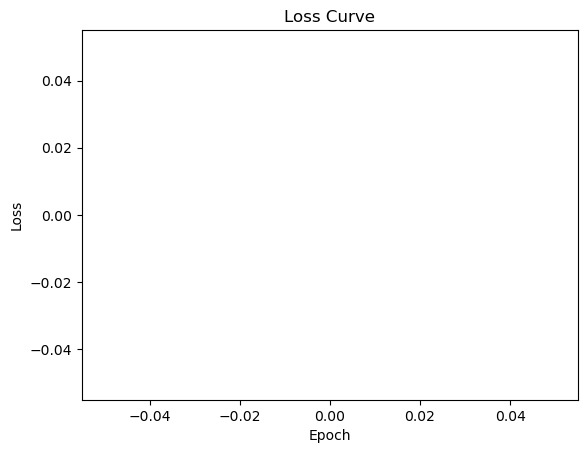

Epoch: 1, Loss: 67.41592938400765 + 0.0im
Epoch: 2, Loss: 67.34823103188414 + 0.0im
Epoch: 3, Loss: 67.27627291879087 + 0.0im
Epoch: 4, Loss: 67.18610087591284 + 0.0im
Epoch: 5, Loss: 67.0762561667011 + 0.0im
Epoch: 6, Loss: 66.94714087448386 + 0.0im
Epoch: 7, Loss: 66.79999059586346 + 0.0im
Epoch: 8, Loss: 66.63638828114905 + 0.0im
Epoch: 9, Loss: 66.45799930561215 + 0.0im
Epoch: 10, Loss: 66.26643872542716 + 0.0im
Epoch: 11, Loss: 66.06321349411603 + 0.0im
Epoch: 12, Loss: 65.84970325706242 + 0.0im
Epoch: 13, Loss: 65.62715918250672 + 0.0im
Epoch: 14, Loss: 65.39671056037935 + 0.0im
Epoch: 15, Loss: 65.15937442872367 + 0.0im
Epoch: 16, Loss: 64.91606582771594 + 0.0im
Epoch: 17, Loss: 64.66760744509813 + 0.0im
Epoch: 18, Loss: 64.41473832858709 + 0.0im
Epoch: 19, Loss: 64.15812176279535 + 0.0im
Epoch: 20, Loss: 63.89835248535946 + 0.0im
Epoch: 21, Loss: 63.635963403004915 + 0.0im
Epoch: 22, Loss: 63.371431825011626 + 0.0im
Epoch: 23, Loss: 63.105185067631496 + 0.0im
Epoch: 24, Loss: 6

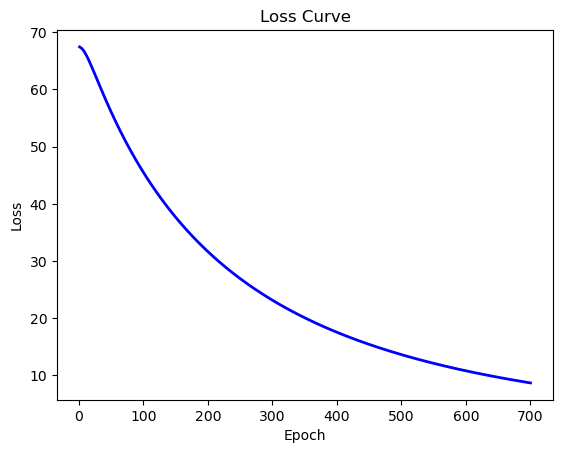

In [ ]:
train(opt,[layer],x,t,D,epochs=700)

In [ ]:
f=Lossfunction(layer(x),t)

8.682661214687663 + 0.0im